# Mini-modèle ALM fonds euros : V1 déterministe

Projection actif-passif d'un fonds euros sur 60 ans, sous quatre scénarios déterministes : central, hausse des taux de 200 pb, baisse de 100 pb, krach actions de 25 %. Données et hypothèses fictives (`data/hypotheses.json`).

Chaque année : rachats (structurels + conjoncturels selon la loi ACPR), revenus financiers, choix du taux servi (participation minimale de 85 %, PPB avec règle des 8 ans, plus-values actions, marge de l'assureur), revalorisation de la PM, paiement des prestations et des frais (0,4 % de l'encours), rééquilibrage de l'actif.

In [1]:
# Fonctionne en local (depuis notebooks/ ou la racine) et dans Google Colab
import os, subprocess, sys
if not os.path.exists("src"):
    if os.path.basename(os.getcwd()) == "notebooks":
        os.chdir("..")
    else:
        if not os.path.exists("mini-alm-fonds-euros"):
            subprocess.run(["git", "clone", "https://github.com/TorjmenYou/mini-alm-fonds-euros.git"], check=True)
        os.chdir("mini-alm-fonds-euros")
sys.path.insert(0, os.getcwd())

import pandas as pd
import matplotlib.pyplot as plt
from src.hypotheses import charger_hypotheses, actif_initial
from src.projection import projeter, scenario, indicateurs

pd.set_option("display.precision", 4)
h = charger_hypotheses()
actif_initial(h)

{'obligations': 926.5, 'actions': 109.0, 'monetaire': 54.5, 'total': 1090.0}

## 1. Scénario central

In [2]:
central = projeter(h, scenario(h, "central"))
colonnes = ["taux_servi", "taux_rachat", "rendement_comptable", "pm", "ppb",
            "pv_actions_realisees", "resultat_assureur", "fonds_propres", "pmvl_obligations"]
central.loc[[0, 1, 2, 4, 6, 8, 10, 20, 30, 40, 60], colonnes].round(4)

,taux_servi,taux_rachat,rendement_comptable,pm,ppb,pv_actions_realisees,resultat_assureur,fonds_propres,pmvl_obligations
annee,,,,,,,,,
0,0.0250,NaN,NaN,1000.0000,40.0000,NaN,NaN,50.0000,-22.6961
1,0.0250,0.05,0.0259,964.0125,30.8696,0.0000,8.3294,58.3294,-18.7445
2,0.0250,0.05,0.0266,929.3201,22.5000,0.8600,8.4094,66.7387,-15.1376
4,0.0250,0.05,0.0315,863.6358,12.6562,5.2116,9.3900,85.1611,-8.9995
6,0.0237,0.05,0.0275,801.5652,7.1191,0.9465,5.0464,97.6552,-4.3685
8,0.0250,0.05,0.0284,744.9107,0.0000,0.8943,6.3390,109.4551,-1.3362
10,0.0224,0.05,0.0294,688.4552,0.0000,0.8468,5.5294,120.3842,0.0000
20,0.0230,0.05,0.0300,467.9721,0.0000,0.6748,6.7176,181.9984,0.0000
30,0.0230,0.05,0.0300,318.1005,0.0000,0.5920,8.4871,258.3296,0.0000


Lecture :
- **Le besoin** : servir le taux cible de 2,5 % net demande 3,2 % brut, chargements de 0,7 % compris.
- **Ce que le portefeuille donne** : il rapporte 2,5 % à 3 %. Seuls 85 % de la part qui correspond aux provisions reviennent aux assurés.
- **Jusqu'à l'année 8** : la PPB, puis la réalisation de plus-values actions et une partie de la marge de l'assureur, comblent l'écart. La PPB est vide en année 8.
- **Ensuite** : le fonds sert environ 2,3 %, un peu sous la cible, et l'assureur abandonne une partie de sa marge chaque année. L'écart au marché (3 %) reste dans la zone où les assurés ne rachètent pas davantage.
- **Le résultat de l'assureur** : il vient des chargements (0,7 %) moins les frais (0,4 %), plus sa part des produits financiers. Il augmente en fin de projection, car les fonds propres sont capitalisés dans le fonds sans être distribués.

Le bilan comptable reste équilibré chaque année (`ecart_bilan` ≈ 0) : VNC de l'actif = PM + PPB + réserve de capitalisation + fonds propres + moins-values en attente d'imputation.

In [3]:
central["ecart_bilan"].abs().max()

np.float64(3.410605131648481e-13)

## 2. Comparaison des scénarios

In [4]:
noms = {"central": "Central", "hausse_taux_200pb": "Taux +200 pb",
        "baisse_taux_100pb": "Taux -100 pb", "krach_actions_25pc": "Actions -25 %"}
resultats = {nom: projeter(h, scenario(h, nom)) for nom in noms}

synthese = pd.DataFrame({noms[n]: indicateurs(df) for n, df in resultats.items()}).T
synthese = synthese[["vm_actif_initial", "be", "be_prestations", "be_frais", "be_garanti", "fdb",
                     "valeur_assureur", "fuite", "pm_residuelle_pct"]]
synthese.columns = ["VM actif initiale", "BE", "dont prestations", "dont frais", "BE garanti", "FDB",
                    "Valeur pour l'assureur", "Fuite", "PM restante à 60 ans"]
synthese.round(2)

,VM actif initiale,BE,dont prestations,dont frais,BE garanti,FDB,Valeur pour l'assureur,Fuite,PM restante à 60 ans
Central,1078.20,966.73,908.20,58.53,666.24,241.97,111.47,0.0,0.10
Taux +200 pb,995.36,932.05,905.34,26.71,743.30,162.04,63.31,-0.0,0.10
Taux -100 pb,1124.47,981.03,921.17,59.86,750.36,170.81,143.43,0.0,0.06
Actions -25 %,1048.23,953.71,895.91,57.80,666.24,229.67,94.52,0.0,0.10


- **BE déterministe** : valeur actuelle des prestations et des frais. S'y ajoute, à l'horizon, ce qui revient encore aux assurés : la PM, la PPB et leur part des plus-values latentes.
- **BE garanti et FDB** : le BE garanti ne valorise que les prestations garanties, la PM revalorisée au TMG de 0 %, avec les mêmes décès et rachats. L'écart entre le BE des prestations et le BE garanti, ce sont les prestations discrétionnaires futures (FDB), c'est-à-dire la participation aux bénéfices future.
- **Valeur pour l'assureur** : valeur de marché de l'actif moins le BE, soit ses fonds propres et la valeur actuelle de ses marges futures. La part des plus-values latentes qui revient aux assurés est déjà dans le BE.
- **Fuite** : sur ces scénarios, chaque actif rapporte exactement le taux d'actualisation en valeur de marché. La valeur initiale de l'actif doit donc se retrouver dans les sorties actualisées plus l'actif final actualisé : un écart signalerait de la valeur créée ou perdue par erreur dans le code.
- **La hausse des taux coûte environ 48 à l'assureur.** L'actif perd environ 83 en valeur de marché, mais le BE ne baisse que d'environ 35. Le passif baisse moins que l'actif pour deux raisons : les assurés rachètent à la valeur comptable, et l'assureur doit relever le taux servi pour suivre le marché. Vendre des obligations ne détruit pas de valeur en plus : la vente change seulement qui supporte la perte.
- **À 60 ans**, il reste environ 10 % de la PM. Allonger encore l'horizon change très peu le BE.

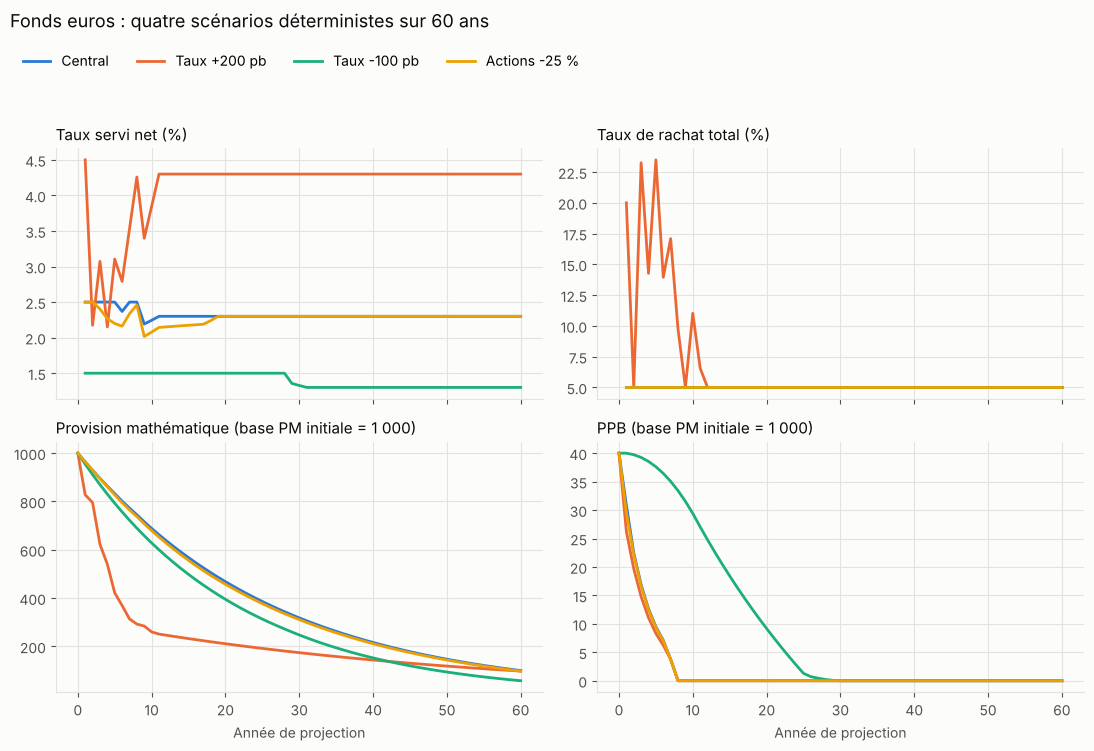

In [5]:
# Palette catégorielle validée (ordre fixe), encre et fond neutres
COULEURS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
ENCRE, ENCRE_2, GRILLE, FOND = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": FOND, "axes.facecolor": FOND, "axes.edgecolor": GRILLE,
    "axes.labelcolor": ENCRE_2, "xtick.color": ENCRE_2, "ytick.color": ENCRE_2,
    "axes.grid": True, "grid.color": GRILLE, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
})

panneaux = [
    ("taux_servi", "Taux servi net", True),
    ("taux_rachat", "Taux de rachat total", True),
    ("pm", "Provision mathématique", False),
    ("ppb", "PPB", False),
]
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5), sharex=True)
for ax, (col, titre, pct) in zip(axes.flat, panneaux):
    for (nom, df), couleur in zip(resultats.items(), COULEURS):
        serie = df[col].loc[1:] if col in ("taux_servi", "taux_rachat") else df[col]
        ax.plot(serie.index, serie * (100 if pct else 1), color=couleur, linewidth=2, label=noms[nom])
    ax.set_title(titre + (" (%)" if pct else " (base PM initiale = 1 000)"), loc="left", color=ENCRE, fontsize=11)
for ax in axes[1]:
    ax.set_xlabel("Année de projection")
fig.suptitle("Fonds euros : quatre scénarios déterministes sur 60 ans", x=0.01, ha="left", y=0.995,
             color=ENCRE, fontsize=13)
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="upper left", bbox_to_anchor=(0.01, 0.955),
           ncol=4, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.91))
fig.savefig("figures/scenarios.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Le choc de +200 pb, année par année

Le cercle vicieux de la hausse des taux : le taux servi décroche du marché, les assurés rachètent, et payer ces rachats oblige à vendre des obligations en moins-value. La réserve de capitalisation étant vide, ces moins-values passent en résultat financier l'année suivante et réduisent la participation.

In [6]:
hausse = resultats["hausse_taux_200pb"]
hausse.loc[0:12, ["taux_10ans", "taux_servi", "taux_rachat", "rachats", "pmv_obligataires_realisees",
                 "report_produits_financiers", "pv_actions_realisees", "reprise_ppb", "abandon_marge",
                 "resultat_assureur", "pmvl_obligations"]].round(3)

,taux_10ans,taux_servi,taux_rachat,rachats,pmv_obligataires_realisees,report_produits_financiers,pv_actions_realisees,reprise_ppb,abandon_marge,resultat_assureur,pmvl_obligations
annee,,,,,,,,,,,
0,0.03,0.025,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-22.696
1,0.05,0.045,0.200,206.910,-8.003,0.000,12.268,13.750,3.553,7.532,-79.652
2,0.05,0.022,0.050,41.859,0.000,-8.003,2.519,6.562,2.584,3.482,-64.692
3,0.05,0.031,0.233,188.750,-6.634,0.000,2.481,4.922,3.763,4.264,-44.454
4,0.05,0.022,0.143,89.883,0.000,-6.634,1.993,3.691,2.109,3.162,-33.857
5,0.05,0.031,0.235,129.483,-1.832,0.000,1.791,2.769,2.667,3.828,-22.728
6,0.05,0.028,0.139,59.860,0.000,-1.832,1.461,2.076,1.897,3.336,-15.391
7,0.05,0.035,0.171,64.685,0.000,0.000,1.332,2.479,1.970,3.752,-9.381
8,0.05,0.043,0.097,31.494,0.000,0.000,1.185,3.750,1.771,3.892,-4.766


Lecture :
- **Année 1** : les assurés comparent le taux servi l'an dernier (2,5 %) au nouveau taux de marché (5 %). L'écart de -2,5 pt déclenche 15 % de rachats conjoncturels, soit 20 % au total. L'assureur mobilise tous ses leviers pour servir 4,5 % : toutes les plus-values actions, la PPB, une partie de sa marge. Il vend aussi des obligations, avec une moins-value de 8.
- **Année 2** : les rachats redeviennent normaux (5 %), car le taux servi en année 1 était proche du marché. Mais les leviers sont épuisés, et la moins-value de l'année 1 ampute les produits financiers : le taux servi tombe à environ 2 %.
- **Années 3 à 8** : un mouvement en dents de scie s'installe. Une année de taux servi bas entraîne, l'année suivante, des rachats massifs (jusqu'à 24 %), donc de nouvelles ventes à perte, qui pèsent à leur tour sur le taux servi.
- **À partir de l'année 9** : le portefeuille, renouvelé à 5 %, ne porte plus de moins-values. Le taux servi remonte vers 4 % et les rachats reviennent vers 5 %.

## 4. Limites de la V1
- Un seul model point, une courbe de taux plate, des scénarios déterministes : pas de TVOG.
- Taux attendu des assurés = taux de marché, sans délai ni concurrence modélisée.
- Pas de PRE ni de provision pour dépréciation durable sur les actions en moins-value.
- Participation aux bénéfices simplifiée : 85 % de la quote-part des produits financiers afférente aux provisions, résultat technique ignoré.
- Frais en pourcentage de l'encours, sans coût par contrat ni inflation.
- Fonds propres capitalisés, sans dividendes.

La V2 passera aux scénarios stochastiques (taux et actions risque neutre) pour calculer un vrai Best Estimate et la TVOG.